# CNN Image Classification Laboration


Images used in this laboration are from [CIFAR10](https://en.wikipedia.org/wiki/CIFAR-10). The CIFAR10 dataset contains 60,000 32x32 color images in 10 different classes. The 10 different classes represent airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, and trucks. There are 6,000 images of each class. 

Your task is to make a classifier, using a convolutional neural network, that can correctly classify each image into the correct class.

Complete the code flagged throughout the elaboration and **answer all the questions in the notebook**.

In [1]:
# Setups
# Automatically reload modules when changed
%reload_ext autoreload
%autoreload 2

# Part 1: Convolutions

In the next sections you will familiarize yourself with 2D convolutions.

## 1.1 What is a convolution?

To understand a bit more about convolutions, we will first test the convolution function in `scipy` using a number of classical filters. 

Convolve the image with Gaussian filter, a Sobel X filter, and a Sobel Y filter, using the function `convolve2d` in `signal` from scipy (see the [documentation](https://docs.scipy.org/doc/scipy-1.15.0/reference/generated/scipy.signal.convolve2d.html
) for more details).


In a CNN, many filters are applied in each layer, and the filter coefficients are learned through back propagation (which is in contrast to traditional image processing, where the filters are designed by an expert).

Run the cell below to define a Gaussian filter and a Sobel X and Y filters.

In [2]:
from scipy import signal
import numpy as np

# Get a test image
from scipy import datasets
image = datasets.ascent()

# Define a help function for creating a Gaussian filter
def matlab_style_gauss2D(shape=(3,3),sigma=0.5):
    """
    2D gaussian mask - should give the same result as MATLAB's
    fspecial('gaussian',[shape],[sigma])
    """
    m,n = [(ss-1.)/2. for ss in shape]
    y,x = np.ogrid[-m:m+1,-n:n+1]
    h = np.exp( -(x*x + y*y) / (2.*sigma*sigma) )
    h[ h < np.finfo(h.dtype).eps*h.max() ] = 0
    sumh = h.sum()
    if sumh != 0:
        h /= sumh
    return h

# Create Gaussian filter with certain size and standard deviation
gaussFilter = matlab_style_gauss2D((15,15),4)

# Define filter kernels for SobelX and Sobely
sobelX = np.array([[ 1, 0,  -1],
                    [2, 0, -2],
                    [1, 0, -1]]) 

sobelY = np.array([[ 1, 2,  1],
                    [0, 0, 0],
                    [-1, -2, -1]]) 

In [3]:
# --------------------------------------------
# === Your code here =========================
# -------------------------------------------- 
# Perform convolution using the function 'convolve2d' for the different filters

filterResponseGauss  = signal.convolve2d(image, gaussFilter, mode='same')
filterResponseSobelX = signal.convolve2d(image, sobelX, mode='same')
filterResponseSobelY = signal.convolve2d(image, sobelY, mode='same')

# ============================================

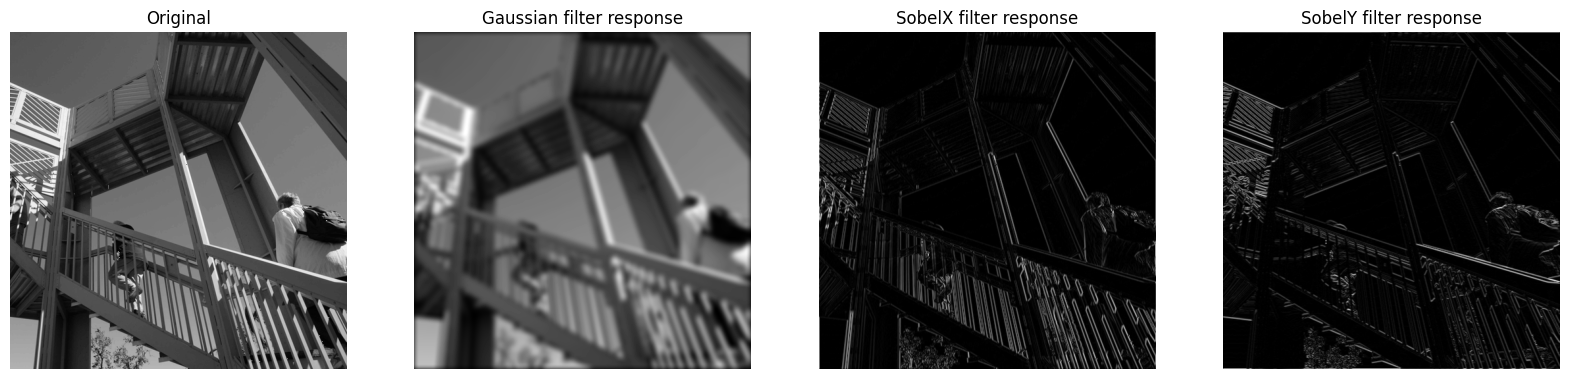

In [4]:
import matplotlib.pyplot as plt

# Show filter responses
fig, (ax_orig, ax_filt1, ax_filt2, ax_filt3) = plt.subplots(1, 4, figsize=(20, 6))
ax_orig.imshow(image, cmap='gray')
ax_orig.set_title('Original')
ax_orig.set_axis_off()
ax_filt1.imshow(np.absolute(filterResponseGauss), cmap='gray')
ax_filt1.set_title('Gaussian filter response')
ax_filt1.set_axis_off()
ax_filt2.imshow(np.absolute(filterResponseSobelX), cmap='gray')
ax_filt2.set_title('SobelX filter response')
ax_filt2.set_axis_off()
ax_filt3.imshow(np.absolute(filterResponseSobelY), cmap='gray')
ax_filt3.set_title('SobelY filter response')
ax_filt3.set_axis_off()

## 1.2 Understanding convolutions

#### **<span style="color:red">Questions</span>**

1. What do the 3 different filters (Gaussian, SobelX, SobelY) do to the original image?

2. What is the size of the original image? How many channels does it have? How many channels does a color image normally have?

3. What is the size of the different filters?

4. What is the size of the filter response if mode 'same' is used for the convolution ?

5. What is the size of the filter response if mode 'valid' is used for the convolution? How does the size of the valid filter response depend on the size of the filter? 

6. Why are 'valid' convolutions a problem for CNNs with many layers?

#### **<span style="color:green">Answers</span>**
[Your answer here]
1) The Gaussian filter blurred the image whereas sobelX and sobelY are mostly black but sobelX has the step railings bright and in sableY we have some parts above the steps bright.
2) The image is 512 x 512 and has only 1 channel i.e., grayscale and a color image has 3 channels (RGB).
3) The Gaussian filter is 15 x 15 and the Sobel filters are 3 x 3.
4) For 'same' mode we got 512 x 512 which is the same size as the input.
5) For 'valid' mode we got 498 x 498 for the Gaussian and 510 x 510 for Sobel. So the bigger the filter, the more the image shrinks.
6) Because the image gets smaller after every layer, so with many layers there will be nothing left.

In [5]:
# --------------------------------------------
# === Your code here =========================
# -------------------------------------------- 
# Your code for checking sizes of image and filter responses
print(f'Image:            {image.shape}   (ndim = {image.ndim}, so 1 channel = grayscale)')
print(f'Gaussian filter:  {gaussFilter.shape}')
print(f'SobelX filter:    {sobelX.shape}')
print(f'SobelY filter:    {sobelY.shape}')
print()

print("mode='same':")
print(f"  Gaussian: {signal.convolve2d(image, gaussFilter, mode='same').shape}")
print(f"  SobelX:   {signal.convolve2d(image, sobelX, mode='same').shape}")

print("mode='valid':")
print(f"  Gaussian (15x15): {signal.convolve2d(image, gaussFilter, mode='valid').shape}")
print(f"  SobelX   (3x3):   {signal.convolve2d(image, sobelX, mode='valid').shape}")

print("mode='full':")
print(f"  Gaussian (15x15): {signal.convolve2d(image, gaussFilter, mode='full').shape}")
print(f"  SobelX   (3x3):   {signal.convolve2d(image, sobelX, mode='full').shape}")

# ============================================

Image:            (512, 512)   (ndim = 2, so 1 channel = grayscale)
Gaussian filter:  (15, 15)
SobelX filter:    (3, 3)
SobelY filter:    (3, 3)

mode='same':
  Gaussian: (512, 512)
  SobelX:   (512, 512)
mode='valid':
  Gaussian (15x15): (498, 498)
  SobelX   (3x3):   (510, 510)
mode='full':
  Gaussian (15x15): (526, 526)
  SobelX   (3x3):   (514, 514)


#  Part 2: Get a graphics card

Skip the next cell if you run on the CPU.

If your computer has a dedicated graphics card and you would like to use it, we need to make sure that our script can see the graphics card that will be used. The graphics cards will perform all the time consuming calculations in every training iteration.

In [6]:
import os
import warnings

# Ignore FutureWarning from numpy
warnings.simplefilter(action='ignore', category=FutureWarning)

import tensorflow as tf

os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
 
# The GPU id to use, usually either "0" or "1";
os.environ["CUDA_VISIBLE_DEVICES"]="0"

# This sets the GPU to allocate memory only as needed
physical_devices = tf.config.experimental.list_physical_devices('GPU')
if len(physical_devices) != 0:
    tf.config.experimental.set_memory_growth(physical_devices[0], True) 
    print("Running on GPU")
else:
    print('No GPU available.')

2026-10-23 02:58:18.342282: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792717098.358233   33689 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792717098.363224   33689 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-23 02:58:18.378765: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Running on GPU


## How fast is the graphics card?


#### **<span style="color:red">Questions</span>**

7. Why are the filters used for a color image of size 7 x 7 x 3, and not 7 x 7 ? 

8. What operation is performed by the 'Conv2D' layer? Is it a standard 2D convolution, as performed by the function signal.convolve2d we just tested?

9.  Pretend that everyone is using an Nvidia RTX 3090 graphics card, how many CUDA cores does it have? How much memory does the graphics card have?

10. How much memory does the graphics card have?

11. What is stored in the GPU memory while training a CNN?

12. Do you think that a graphics card, compared to the CPU, is equally faster for convolving a batch of 1,000 images, compared to convolving a batch of 3 images? Motivate your answer.


#### **<span style="color:green">Answers</span>**
[Your answer here]

7) Because a color image contains 3 channels, so the filter has to include all 3 channels.
8) Conv2D performs sum by going over all the input channeles whereas convolve2d works only on one channel, so it is not the same.
9) It has 10,496 CUDA cores and 24 GB memory.
10) The RTX 3090 has 24 GB and the one we used i.e., RTX 3060 Laptop GPU has 6 GB.
11) The weights, gradients, the batch of images and the outputs of each layer are stored in teh GPU memory while training a CNN.
12) No, for 1,000 images the GPU is a lot faster than the CPU because it has thousands of cores that can convolve many images in parallel, whereas for 3 images most of the cores are not used and copying the data to the GPU takes most of the time, so it is not much faster than the CPU.

# Part 3: Dataset

In the following section you will load the CIFAR10 dataset, check few samples, perform some preprocessing on the images and the labels, and split the data into training, validation and testing.

## 3.1 Load the dataset

Run the following section to load the CIFAR10 data, take a total of 10.000 training/validation samples and 2000 testing samples. 

In [7]:
from keras.datasets import cifar10
import numpy as np

classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Download CIFAR train and test data
(X, Y), (Xtest, Ytest) = cifar10.load_data()

print("Training/validation images have size {} and labels have size {} ".format(X.shape, Y.shape))
print("Test images have size {} and labels have size {} \n ".format(Xtest.shape, Ytest.shape))

# Reduce the number of images for training/validation and testing to 10000 and 2000 respectively, 
# to reduce processing time for this elaboration. 
X = X[0:10000]
Y = Y[0:10000]

Xtest = Xtest[0:2000]
Ytest = Ytest[0:2000]

Ytestint = Ytest

print("Reduced training/validation images have size %s and labels have size %s " % (X.shape, Y.shape))
print("Reduced test images have size %s and labels have size %s \n" % (Xtest.shape, Ytest.shape))

# Check that we have some training examples from each class
for i in range(10):
    print("Number of training/validation examples for class {} is {}" .format(i,np.sum(Y == i)))

Training/validation images have size (50000, 32, 32, 3) and labels have size (50000, 1) 
Test images have size (10000, 32, 32, 3) and labels have size (10000, 1) 
 
Reduced training/validation images have size (10000, 32, 32, 3) and labels have size (10000, 1) 
Reduced test images have size (2000, 32, 32, 3) and labels have size (2000, 1) 

Number of training/validation examples for class 0 is 1005
Number of training/validation examples for class 1 is 974
Number of training/validation examples for class 2 is 1032
Number of training/validation examples for class 3 is 1016
Number of training/validation examples for class 4 is 999
Number of training/validation examples for class 5 is 937
Number of training/validation examples for class 6 is 1030
Number of training/validation examples for class 7 is 1001
Number of training/validation examples for class 8 is 1025
Number of training/validation examples for class 9 is 981


Lets look at some of the training examples, this cell is already finished. You will see different examples every time you run the cell.

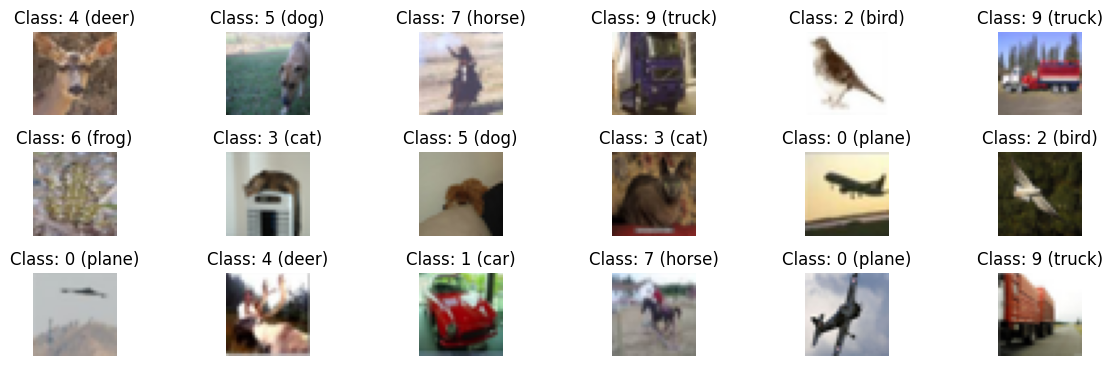

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
for i in range(18):
    idx = np.random.randint(7500)
    label = Y[idx,0]
    
    plt.subplot(3,6,i+1)
    plt.tight_layout()
    plt.imshow(X[idx])
    plt.title("Class: {} ({})".format(label, classes[label]))
    plt.axis('off')
plt.show()

##  3.2 Split data into training, validation and testing
Split your data (X, Y) into training (Xtrain, Ytrain) and validation (Xval, Yval), so that we have training, validation and test datasets (as in the previous laboration).

We use the `train_test_split` function from scikit learn (see the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) for more details) to obtain 25% validation set.

In [9]:
from sklearn.model_selection import train_test_split

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# split the original dataset into 70% Training and 30% Temp
Xtrain, Xval, Ytrain, Yval = train_test_split(X, Y, test_size=0.25, random_state=1234,
                                              shuffle=True, stratify=Y)



# Print the size of training data, validation data and test data
print(f'Xtrain size {Xtrain.shape}, Ytrain size {Ytrain.shape}')
print(f'Xval size {Xval.shape}, Yval size {Yval.shape}')
print(f'Xtest size {Xtest.shape}, Ytest size {Ytest.shape}')

# ============================================

Xtrain size (7500, 32, 32, 3), Ytrain size (7500, 1)
Xval size (2500, 32, 32, 3), Yval size (2500, 1)
Xtest size (2000, 32, 32, 3), Ytest size (2000, 1)


## 3.3 Image Preprocessing

Lets perform some preprocessing. The images are stored as uint8, i.e. 8 bit unsigned integers, but need to be converted to 32 bit floats. We also make sure that the range is -1 to 1, instead of 0 - 255.

In [10]:
# Convert datatype for Xtrain, Xval, Xtest, to float32
Xtrain = Xtrain.astype('float32')
Xval = Xval.astype('float32')
Xtest = Xtest.astype('float32')

# Change range of pixel values to [-1,1]
Xtrain = Xtrain / 127.5 - 1
Xval = Xval / 127.5 - 1
Xtest = Xtest / 127.5 - 1

##  3.4 Label preprocessing

The labels (Y) need to be converted from e.g. '4' to "hot encoded", i.e. to a vector of type [0, 0, 0, 1, 0, 0, 0, 0, 0, 0] . We use the `to_categorical`function in Keras (see the [documentation](https://keras.io/api/utils/python_utils/#to_categorical-function) for details on how to use it)

In [11]:
from tensorflow.keras.utils import to_categorical

# Print shapes before converting the labels
print('Ytrain has size {}.'.format(Ytrain.shape))
print('Yval has size {}.'.format(Yval.shape))
print('Ytest has size {}.'.format(Ytest.shape))


# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Your code for converting Ytrain, Yval, Ytest to categorical
Ytrain = to_categorical(Ytrain, 10)
Yval = to_categorical(Yval, 10)
Ytest = to_categorical(Ytest, 10)

# Print shapes after converting the labels
print()
print('Ytrain has size {}.'.format(Ytrain.shape))
print('Yval has size {}.'.format(Yval.shape))
print('Ytest has size {}.'.format(Ytest.shape))

# ============================================

Ytrain has size (7500, 1).
Yval has size (2500, 1).
Ytest has size (2000, 1).

Ytrain has size (7500, 10).
Yval has size (2500, 10).
Ytest has size (2000, 10).


# Part 4: 2D CNN

In the following sections you will build a 2D CNN model and will train it to perform classification on the CIFAR10 dataset. 

## 4.1 Build CNN model

Start by implementing the `build_CNN` function in the `utilities.py` file. Below you can find the specifications on how your `build_CNN` function should build the model:
- Each convolutional layer is composed by: `2D convolution` -> `batch normalization` -> `max pooling`.
- The `2D convolution` uses a 3 x 3 kernel size, padding='same' and a number of starting filter that is an input to the `build_CNN` function. The number of filters doubles with each convolutional layer (e.g. 32, 64, 128, etc.)
- The max pooling layers should have a pool size of 2 x 2.
- After the convolutional layers comes a flatten layer, followed by a number of intermediate dense layers. 
- The number of nodes in the intermediate dense layers before the final dense layer is an input to the `build_CNN` function. The intermediate dense layers use `relu` activation functions and each is followed by `batch normalization`.
- The final dense layer should have 10 nodes (=the number of classes in this elaboration) and `softmax` activation. 

Here are some relevant functions that you should use in `build_CNN`. For a complete list of functions and their definitions see the [keras documentation](https://keras.io/api/):

- `model.add()`, adds a layer to the network;
- `Dense()`, a dense network layer. See the [documentation](https://keras.io/api/layers/core_layers/dense/) what are the input options and outputs of the `Dense()` function. 
- `Conv2D()` performs 2D convolutions with a number of filters with a certain size (e.g. 3 x 3) (see [documentation](https://keras.io/api/layers/convolution_layers/convolution2d/)). 
- `BatchNormalization()`, perform batch normalization (see [documentation](https://keras.io/api/layers/normalization_layers/batch_normalization/)).
- `MaxPooling2D()`, saves the max for a given pool size, results in down sampling (see [documentation](https://keras.io/api/layers/pooling_layers/max_pooling2d/)).
- `Flatten()`, flatten a multi-channel tensor into a long vector (see [documentation](https://keras.io/api/layers/reshaping_layers/flatten/)).
- `model.compile()`, compiles the model. You can set the input metrics=['accuracy'] to print the classification accuracy during the training.
- cost and loss functions: check the [documentation](https://keras.io/losses/) and chose a loss function for binary classification.

To get more information in model [compile](https://keras.io/api/models/model_training_apis/#compile-method), [training](https://keras.io/api/models/model_training_apis/#fit-method) and [evaluation](https://keras.io/api/models/model_training_apis/#evaluate-method) see the relevant documentation.

Here you can start with the `Adam` optimizer when compiling the model.

Use the following cell to test your `build_CNN` utility function. Remember to import a relevant cost function for multi-class classification from [keras.losses](https://keras.io/losses/) which relates to how many classes you have.

In [12]:
# import utilities
from utilities import build_CNN

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# import a suitable loss function from keras.losses and use as input to the build_DNN function.
from tf_keras.losses import CategoricalCrossentropy

# Build a DNN model following the specifications above
model = build_CNN((32, 32, 3), CategoricalCrossentropy(),
                  n_conv_layers=2, n_filters=16, n_dense_layers=0,
                  learning_rate=0.01, act_fun='relu', optimizer='adam',
                  print_summary=True)

# ============================================

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 32, 32, 16)        448       
                                                                 
 batch_normalization (Batch  (None, 32, 32, 16)        64        
 Normalization)                                                  
                                                                 
 max_pooling2d (MaxPooling2  (None, 16, 16, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 16, 16, 32)        4640      
                                                                 
 batch_normalization_1 (Bat  (None, 16, 16, 32)        128       
 chNormalization)                                                
                                                        

I0000 00:00:1792717104.089958   33689 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


## 4.2 Train 2D CNN

Time to train the CNN!

Start with a model with 2 convolutional layers where the first layer has have 16 filters, and with no intermediate dense layers.

Set the training parameters, build the model and run the training. 

Use the following training parameters:
- `batch_size=20`
- `epochs=20`
- `learning_rate=0.01`

Relevant functions:
- `build_CNN`, the function that you defined in the `utilities.py` file.
- `model.fit()`, train the model with some training data (see [documentation](https://keras.io/api/models/model_training_apis/#fit-method)).
- `model.evaluate()`, apply the trained model to some test data (see [documentation](https://keras.io/api/models/model_training_apis/#evaluate-method)).

## 2 convolutional layers, no intermediate dense layers

In [13]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Setup some training parameters
batch_size = 20
epochs = 20
input_shape = Xtrain.shape[1:]
learning_rate = 0.01
loss = CategoricalCrossentropy()

# Build model
model1 = build_CNN(input_shape, loss,
                   n_conv_layers=2, n_filters=16, n_dense_layers=0,
                   learning_rate=learning_rate, act_fun='relu', optimizer='adam',
                   print_summary=True)

# Train the model  using training data and validation data
history1 = model1.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      verbose=1)

# ============================================

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 32, 32, 16)        448       
                                                                 
 batch_normalization_2 (Bat  (None, 32, 32, 16)        64        
 chNormalization)                                                
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 16, 16, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_3 (Conv2D)           (None, 16, 16, 32)        4640      
                                                                 
 batch_normalization_3 (Bat  (None, 16, 16, 32)        128       
 chNormalization)                                                
                                                      

I0000 00:00:1792717105.258234   33775 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1792717105.766974   33775 service.cc:148] XLA service 0x7c0c1146db40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792717105.767058   33775 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6
2026-10-23 02:58:25.774224: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792717105.969825   33775 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


375/375 [==============================] - 4s 6ms/step - loss: 2.5284 - accuracy: 0.3580 - val_loss: 1.6395 - val_accuracy: 0.4072
Epoch 2/20
375/375 [==============================] - 2s 6ms/step - loss: 1.4504 - accuracy: 0.4831 - val_loss: 1.4578 - val_accuracy: 0.4740
Epoch 3/20
375/375 [==============================] - 2s 6ms/step - loss: 1.3151 - accuracy: 0.5331 - val_loss: 1.5242 - val_accuracy: 0.4708
Epoch 4/20
375/375 [==============================] - 2s 6ms/step - loss: 1.2161 - accuracy: 0.5697 - val_loss: 1.3671 - val_accuracy: 0.5408
Epoch 5/20
375/375 [==============================] - 2s 6ms/step - loss: 1.1205 - accuracy: 0.6071 - val_loss: 1.4900 - val_accuracy: 0.4904
Epoch 6/20
375/375 [==============================] - 2s 5ms/step - loss: 1.0509 - accuracy: 0.6281 - val_loss: 1.4323 - val_accuracy: 0.5296
Epoch 7/20
375/375 [==============================] - 2s 5ms/step - loss: 1.0058 - accuracy: 0.6481 - val_loss: 1.3347 - val_accuracy: 0.5620
Epoch 8/20
375/37

In [14]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Evaluate the trained model on test set, not used in training or validation
score = model1.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

Test loss: 2.6392
Test accuracy: 0.5195


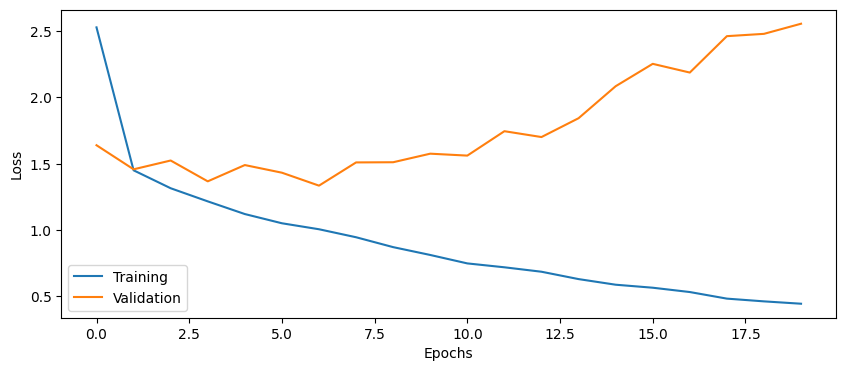

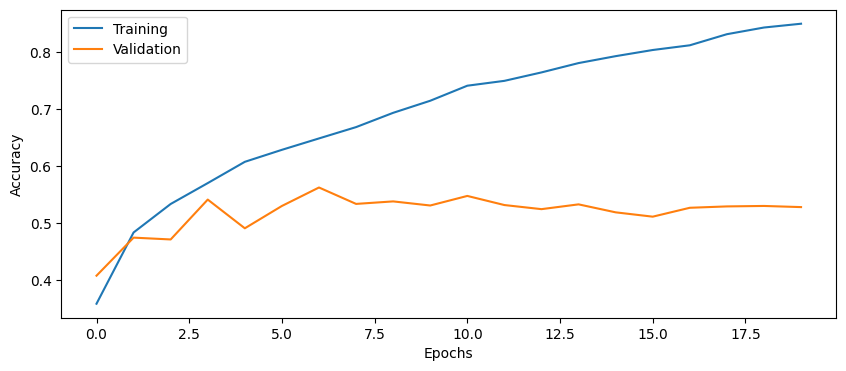

In [15]:
from utilities import plot_results
# Plot the history from the training run
plot_results(history1)

##  4.3 Improving model performance

Write down the test accuracy, are you satisfied with the classifier performance (random chance is 10%)? 

#### **<span style="color:red">Questions</span>**
13. How big is the difference between training and test accuracy?

14. For the DNN elaboration we used a batch size of 10.000, why do we need to use a smaller batch size in this elaboration?

#### **<span style="color:green">Answers</span>**
[Your answer here]

I got a test accuracy of 0.5195, which is a lot better than random chance (10 %), but I am not satisfied because almost half of the test images are still classified wrong

13) I got the training accuracy at the end is 0.8495 whereas the test accuracy is 0.5195, so the difference is around 33 %.
    
14) Because in a CNN each image creates big feature maps in every layer which have to be stored in the GPU memory, so a batch of 10,000 images will not fit in the GPU memory and a smaller batch also gives more weight updates per epoch.

Experiment with several model configurations in the following sections. 

### 2 convolutional layers with 16 starting filters and 1 intermediate dense layer (50 nodes)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 32, 32, 16)        448       
                                                                 
 batch_normalization_4 (Bat  (None, 32, 32, 16)        64        
 chNormalization)                                                
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 16, 16, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 16, 16, 32)        4640      
                                                                 
 batch_normalization_5 (Bat  (None, 16, 16, 32)        128       
 chNormalization)                                                
                                                      

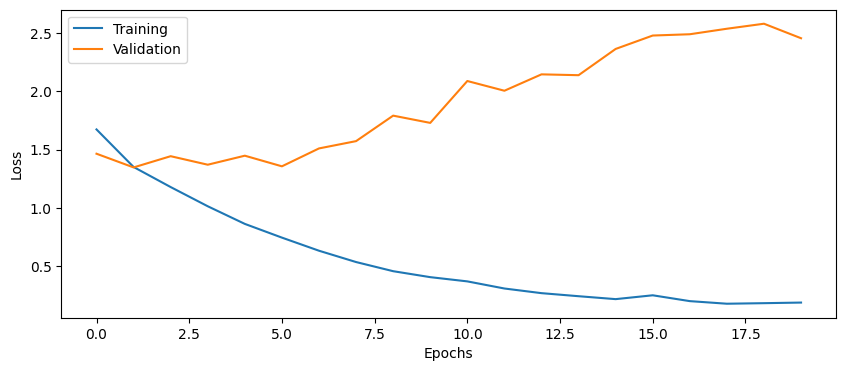

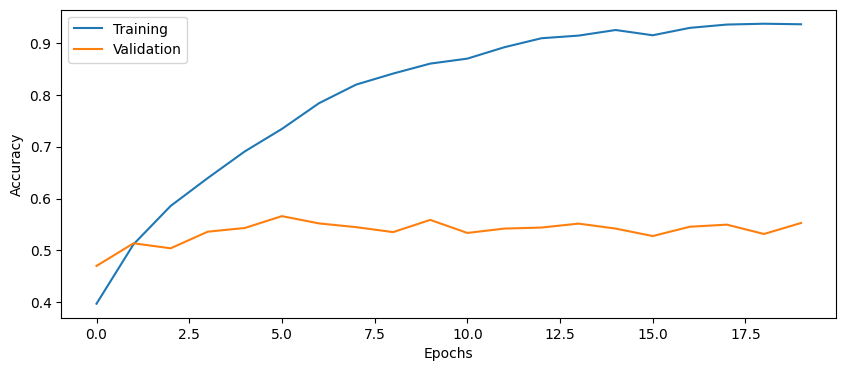

In [16]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Build and train model
model1 = build_CNN(input_shape, loss,
                   n_conv_layers=2, n_filters=16, n_dense_layers=1, n_nodes=50,
                   learning_rate=learning_rate, act_fun='relu', optimizer='adam',
                   print_summary=True)

history1 = model1.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      verbose=1)

# Evaluate model on test data
score = model1.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history1)

### 4 convolutional layers with 16 starting filters and 1 intermediate dense layer (50 nodes)

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 32, 32, 16)        448       
                                                                 
 batch_normalization_7 (Bat  (None, 32, 32, 16)        64        
 chNormalization)                                                
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 16, 16, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 16, 16, 32)        4640      
                                                                 
 batch_normalization_8 (Bat  (None, 16, 16, 32)        128       
 chNormalization)                                                
                                                      

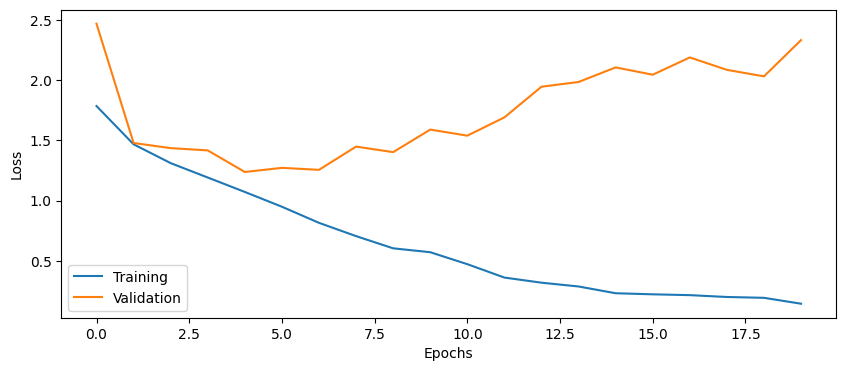

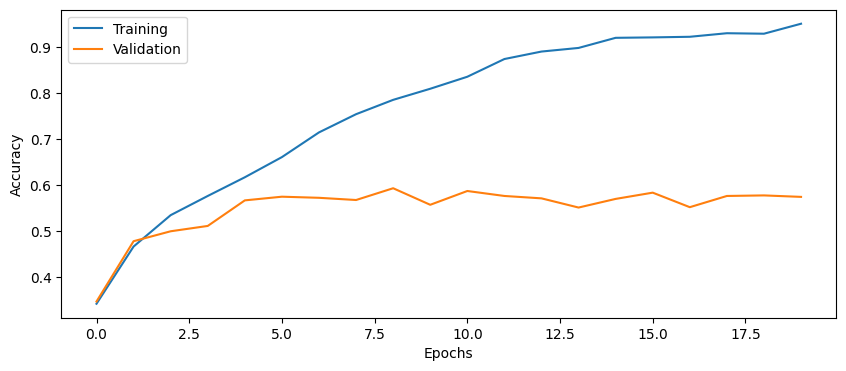

In [17]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Build and train model
model2 = build_CNN(input_shape, loss,
                   n_conv_layers=4, n_filters=16, n_dense_layers=1, n_nodes=50,
                   learning_rate=learning_rate, act_fun='relu', optimizer='adam',
                   print_summary=True)

history2 = model2.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      verbose=1)

# Evaluate model on test data
score = model2.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history2)

## 4.4 Plot the CNN architecture and understand the internal model dimensions

To understand your network better, print the architecture using `model.summary()`

#### **<span style="color:red">Questions</span>**

15. How many trainable parameters does your network have? Which part of the network contains most of the parameters?
    
16. What is the input to and output of a Conv2D layer? What are the dimensions of the input and output? 
17. Is the batch size always the first dimension of each 4D tensor? Check the [documentation](https://keras.io/layers/convolutional/) for Conv2D.
18. If a convolutional layer that contains 128 filters is applied to an input with 32 channels, what is the number of channels in the output?
19. Why is the number of parameters in each Conv2D layer *not* equal to the number of filters times the number of filter coefficients per filter (plus biases)?
20. How does MaxPooling help in reducing the number of parameters to train?

#### **<span style="color:green">Answers</span>**
[Your answer here]

15) My network has 124,180 trainable parameters and most of them are in the conv layers, especially the last conv layer with 128 filters.
16) The input to a Conv2D layer is the image or the feature maps from the previous layer and the output is new feature maps. Both are 4D tensors i.e., batch, height, width, channels, for example in my network the first Conv2D layer has input (None, 32, 32, 3) and output (None, 32, 32, 16) and the second one has input (None, 16, 16, 16) and output (None, 16, 16, 32), so the height and width stay the same and the number of channels becomes the number of filters.
17) Yes, the batch size is always the first dimension and it is shown as None in the summary.
18) The output will have 128 channels because each filter gives one output channel.
19) Because each filter does not only have 3*3 coefficients, it also goes over all the input channels, so every filter has 3 * 3 * (number of input channels) coefficients. For example, the second Conv2D layer in my network has 16 input channels and 32 filters, so it has 32 * (3 *3 *16) + 32 = 4,640 parameters and not 32 *(3 *3) + 32 = 320.
20) MaxPooling makes the height and width of the image half, so after Flatten we get fewer values and the dense layer needs fewer weights which reduces the number of parameters to train.

##  4.5 Dropout regularization

Add dropout regularization between each intermediate dense layer, with dropout probability 50%.

#### **<span style="color:red">Questions</span>**

21. How much did the test accuracy improve with dropout, compared to without dropout?

22. What other types of regularization can be applied? How can you add `L2 regularization` for the convolutional layers?
 
#### **<span style="color:green">Answers</span>**
[Your answer here]

21) The test accuracy did not improve with dropout, I got 0.5750 with dropout whereas without dropout it was 0.5865, so it is almost the same but the training accuracy is lower i.e., 0.8880 vs 0.9515 which means there is less overfitting.

22) Other types of regularization are L1/L2 regularization, data augmentation and early stopping and for L2 regularization we can add kernel_regularizer=l2(0.001) in the Conv2D layers which adds a penalty for large weights. 

### 4 convolutional layers with 16 starting filters and 1 intermediate dense layer (50 nodes) with dropout

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_10 (Conv2D)          (None, 32, 32, 16)        448       
                                                                 
 batch_normalization_12 (Ba  (None, 32, 32, 16)        64        
 tchNormalization)                                               
                                                                 
 max_pooling2d_10 (MaxPooli  (None, 16, 16, 16)        0         
 ng2D)                                                           
                                                                 
 conv2d_11 (Conv2D)          (None, 16, 16, 32)        4640      
                                                                 
 batch_normalization_13 (Ba  (None, 16, 16, 32)        128       
 tchNormalization)                                               
                                                      

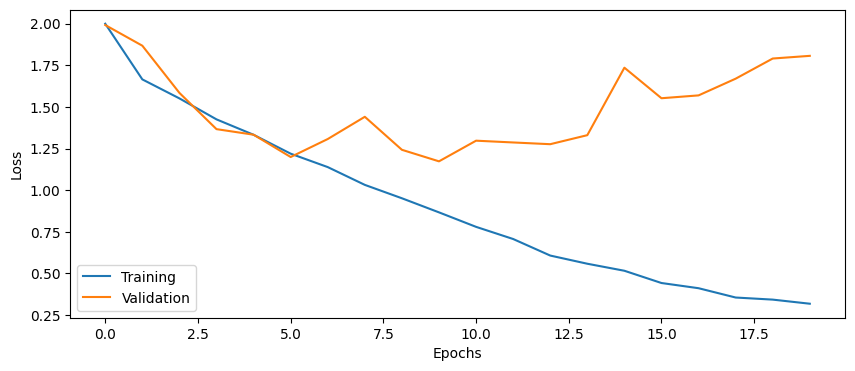

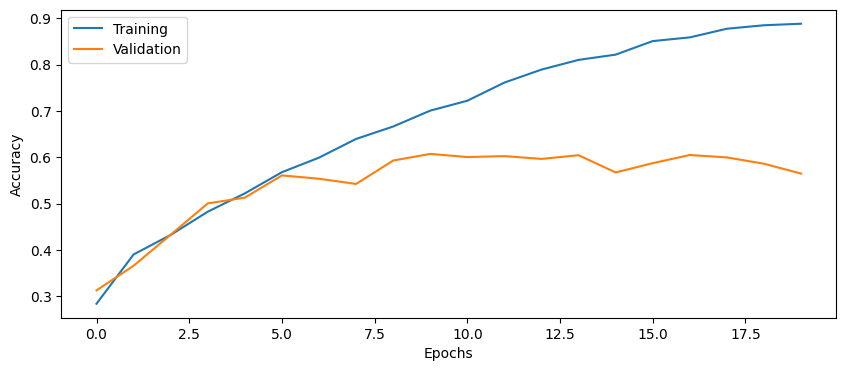

In [18]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Setup some training parameters
batch_size = 20
epochs = 20
input_shape = Xtrain.shape[1:]
learning_rate = 0.01

# Build and train model
model3 = build_CNN(input_shape, loss,
                   n_conv_layers=4, n_filters=16, n_dense_layers=1, n_nodes=50,
                   use_dropout=True,
                   learning_rate=learning_rate, act_fun='relu', optimizer='adam',
                   print_summary=True)

# Train the model using training data and validation data
history3 = model3.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      verbose=1)

# Evaluate model on test data
score = model3.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

plot_results(history3)

##  4.6 Tweaking model performance

You have now seen the basic building blocks of a 2D CNN. To further improve performance involves changing the number of convolutional layers, the number of filters per layer, the number of intermediate dense layers, the number of nodes in the intermediate dense layers, batch size, learning rate, number of epochs, etc. Spend some time (30 - 90 minutes) testing different settings.

#### **<span style="color:red">Questions</span>**

23. How high test accuracy can you obtain? What is your best configuration?

#### **<span style="color:green">Answers</span>**
23) The highest test accuracy I got is 0.6230 and my best configuration is 3 conv layers, 32 starting filters, 1 dense layer with 128 nodes, dropout, batch size 32, learning rate 0.001 and 40 epochs.

## *Your best config*

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_14 (Conv2D)          (None, 32, 32, 32)        896       
                                                                 
 batch_normalization_17 (Ba  (None, 32, 32, 32)        128       
 tchNormalization)                                               
                                                                 
 max_pooling2d_14 (MaxPooli  (None, 16, 16, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_15 (Conv2D)          (None, 16, 16, 64)        18496     
                                                                 
 batch_normalization_18 (Ba  (None, 16, 16, 64)        256       
 tchNormalization)                                               
                                                      

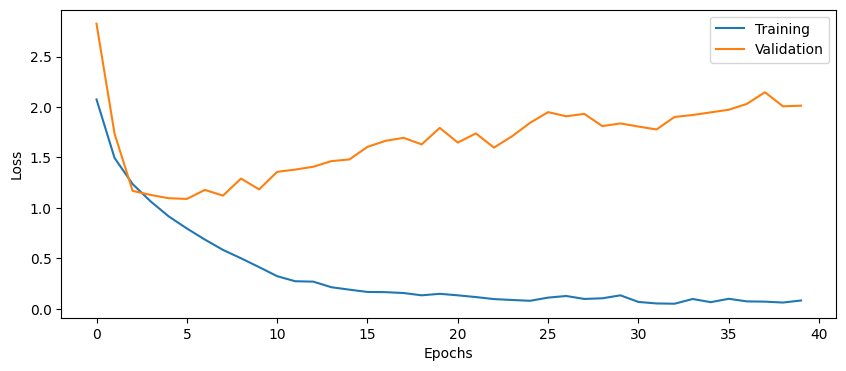

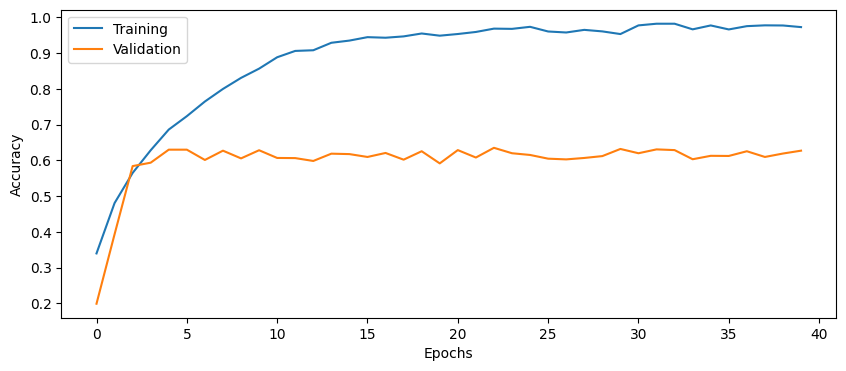

In [19]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Setup some training parameters
batch_size = 32
epochs = 40
input_shape = Xtrain.shape[1:]
learning_rate = 0.001

# Build and train model. Here experiment with several model architecture configurations to obtain the best performance.
model4 = build_CNN(input_shape, loss,
                   n_conv_layers=3, n_filters=32, n_dense_layers=1, n_nodes=128,
                   use_dropout=True,
                   learning_rate=learning_rate, act_fun='relu', optimizer='adam',
                   print_summary=True)

history4 = model4.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      verbose=1)

# Evaluate model on test data
score = model4.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history4)

# Part 5: Model generalization

How high is the test accuracy if we rotate the test images? In other words, how good is the CNN at generalizing to rotated images?

Rotate each test image 90 degrees, the cells are already finished.

#### **<span style="color:red">Questions</span>**

24. What is the test accuracy for rotated test images, compared to test images without rotation? Explain the difference in accuracy.

#### **<span style="color:green">Answers</span>**
[Your answer here]

24) For the rotated test images I got 0.2220 whereas for the test images without rotation I got 0.6230, because the model was only trained on upright images so it cannot recognize the rotated ones.


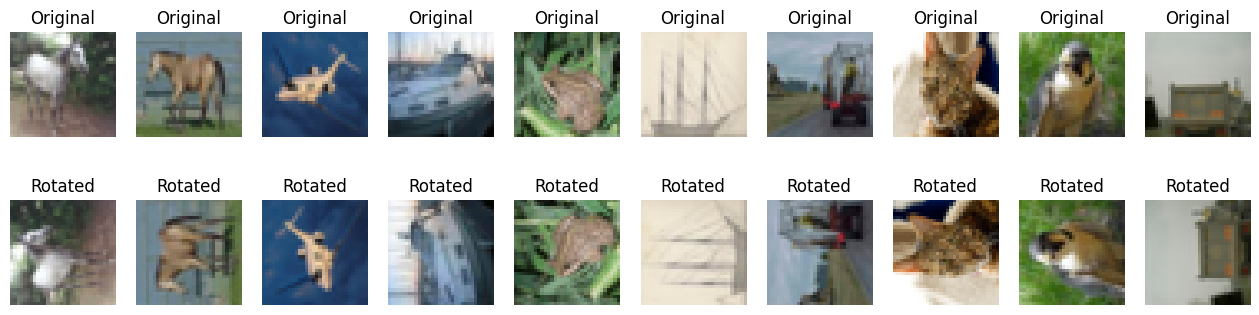

In [32]:
from utilities import myrotate
# Visualize some rotated images
# Rotate the test images 90 degrees
Xtest_rotated = myrotate(Xtest)

# Look at some rotated images
plt.figure(figsize=(16,4))
for i in range(10):
    idx = np.random.randint(500)
    
    plt.subplot(2,10,i+1)
    plt.imshow(Xtest[idx]/2+0.5)
    plt.title("Original")
    plt.axis('off')
    
    plt.subplot(2,10,i+11)
    plt.imshow(Xtest_rotated[idx]/2+0.5)
    plt.title("Rotated")
    plt.axis('off')
plt.show()


In [21]:
# Evaluate the trained model on rotated test set
score = model4.evaluate(Xtest_rotated, Ytest, verbose=0)
print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

Test loss: 6.2769
Test accuracy: 0.2220


##  5.1 Augmentation using Keras `ImageDataGenerator`

We can increase the number of training images through data augmentation (we now ignore that CIFAR10 actually has 60 000 training images). Image augmentation is about creating similar images, by performing operations such as rotation, scaling, elastic deformations and flipping of existing images. This will prevent overfitting, especially if all the training images are in a certain orientation.

We will perform the augmentation on the fly, using a built-in function in Keras, called `ImageDataGenerator`. In particular, we will use the `flow()` functionality (see the [documentation](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator) for more details).

Make sure to use different subsets for training and validation when you calling `flow()` on the training data generator in `model.fit()`, otherwise you will validate on the same data. 

In [22]:
# Get all 60 000 training images again. ImageDataGenerator manages validation data on its own

# re-load the CIFAR10 train and test data
(X, Y), (Xtest, Ytest) = cifar10.load_data()

# Reduce the number of images for training/validation and testing to 10000 and 2000 respectively, 
# to reduce processing time for this elaboration. 
X = X[0:10000]
Y = Y[0:10000]

Xtest = Xtest[0:2000]
Ytest = Ytest[0:2000]

# Change data type and rescale range
X = X.astype('float32')
Xtest = Xtest.astype('float32')

X = X / 127.5 - 1
Xtest = Xtest / 127.5 - 1


# Convert labels to hot encoding
Y = to_categorical(Y, 10)
Ytest = to_categorical(Ytest, 10)

print("Training/validation images have size {} and labels have size {} ".format(X.shape, Y.shape))
print("Test images have size {} and labels have size {} \n ".format(Xtest.shape, Ytest.shape))

Training/validation images have size (10000, 32, 32, 3) and labels have size (10000, 10) 
Test images have size (2000, 32, 32, 3) and labels have size (2000, 10) 
 


In [23]:
from tf_keras.preprocessing.image import ImageDataGenerator

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Use a rotation range of 30 degrees, horizontal and vertical flipping
# Set up image data generator
image_dataset = ImageDataGenerator(rotation_range=30,
                                   horizontal_flip=True,
                                   vertical_flip=True,
                                   validation_split=0.25)

train_flow = image_dataset.flow(X, Y, batch_size=1, subset='training')


# ============================================


#### **<span style="color:red">Questions</span>**

25. How would you change the code for the image generator if you cannot fit all training images in CPU memory? What is the disadvantage of doing that change?

#### **<span style="color:green">Answers</span>**
25) We can use flow_from_directory() instead of flow() method so the images are read from the disk batch by batch instead of keeping all of them in memory and the disadvantage is that the training gets slower because the images have to be read from the disk every epoch.

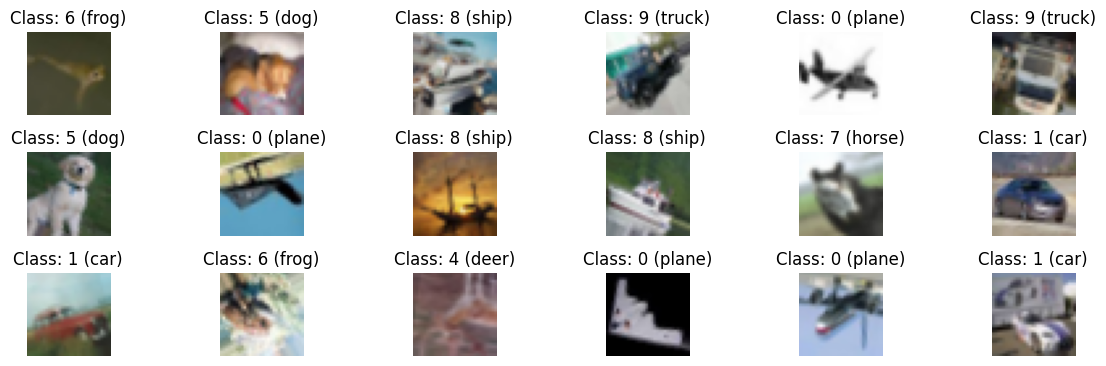

In [24]:
# Plot some augmented images

plt.figure(figsize=(12,4))
for i in range(18):
    (im, label) = train_flow.next()
    im = (im[0] + 1) * 127.5
    im = im.astype('int')
    label = np.flatnonzero(label)[0]
    
    plt.subplot(3,6,i+1)
    plt.tight_layout()
    plt.imshow(im)
    plt.title("Class: {} ({})".format(label, classes[label]))
    plt.axis('off')
plt.show()

## 5.2 Train the CNN with images from the generator

Check the documentation for the [`model.fit`](https://keras.io/api/models/model_training_apis/#fit-method) method how to use it with a generator instead of a fix dataset (numpy arrays).

To make the comparison fair to training without augmentation

- `steps_per_epoch` should be set to: `len(Xtrain)/batch_size`
- `validation_steps` should be set to: `len(Xval)/batch_size`
    
This is required since with a generator, the fit function will not know how many examples your original dataset has.

#### **<span style="color:red">Questions</span>**

26. How quickly is the training accuracy increasing compared to without augmentation? Explain why there is a difference compared to without augmentation. We are here talking about the number of training epochs required to reach a certain accuracy, and not the training time in seconds. What parameter is necessary to change to perform more training?

27. What other types of image augmentation can be applied, compared to what we use here?

#### **<span style="color:green">Answers</span>**

26) The training accuracy increases much slower with augmentation, after 20 epochs I got only 0.60 whereas without augmentation it was already 0.95, and even after 60 epochs it is only 0.72, because every epoch the images are randomly rotated and flipped, so the model sees different images every time and cannot memorize them and to perform more training we have to increase the number of epochs.

27) Here we use rotation and flipping and other types of augmentation are shifting the image, zooming, shearing, changing brightness, cropping and adding noise.

In [25]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Setup training parameters
batch_size = 32
epochs = 60
input_shape = X.shape[1:]

# Build model (your best config)
model6 = build_CNN(input_shape, loss,
                   n_conv_layers=3, n_filters=32, n_dense_layers=1, n_nodes=128,
                   use_dropout=True,
                   learning_rate=0.001, act_fun='relu', optimizer='adam',
                   print_summary=True)

# Set up training and validation dataset flows from image_dataset
# flow() for training data
train_flow = image_dataset.flow(X, Y, batch_size=batch_size, subset='training')

# flow() for validation data
val_flow = image_dataset.flow(X, Y, batch_size=batch_size, subset='validation')


# Train the model using on the fly augmentation
history6 = model6.fit(train_flow,
                      steps_per_epoch=len(Xtrain) // batch_size,
                      epochs=epochs,
                      validation_data=val_flow,
                      validation_steps=len(Xval) // batch_size,
                      verbose=1)

# ============================================

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_17 (Conv2D)          (None, 32, 32, 32)        896       
                                                                 
 batch_normalization_21 (Ba  (None, 32, 32, 32)        128       
 tchNormalization)                                               
                                                                 
 max_pooling2d_17 (MaxPooli  (None, 16, 16, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_18 (Conv2D)          (None, 16, 16, 64)        18496     
                                                                 
 batch_normalization_22 (Ba  (None, 16, 16, 64)        256       
 tchNormalization)                                               
                                                      

In [26]:
# Check if there is still a big difference in accuracy for original and rotated test images

# Evaluate the trained model on original test set
score = model6.evaluate(Xtest, Ytest, batch_size = batch_size, verbose=0)
print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Evaluate the trained model on rotated test set
score = model6.evaluate(Xtest_rotated, Ytest, batch_size = batch_size, verbose=0)
print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

Test loss: 1.0164
Test accuracy: 0.6510
Test loss: 2.5501
Test accuracy: 0.3230


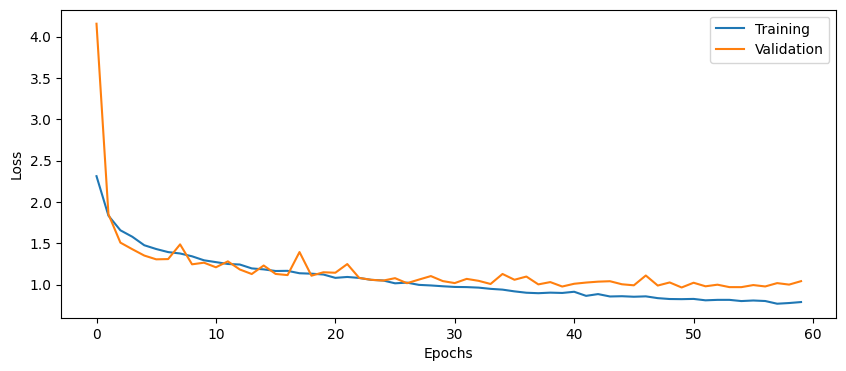

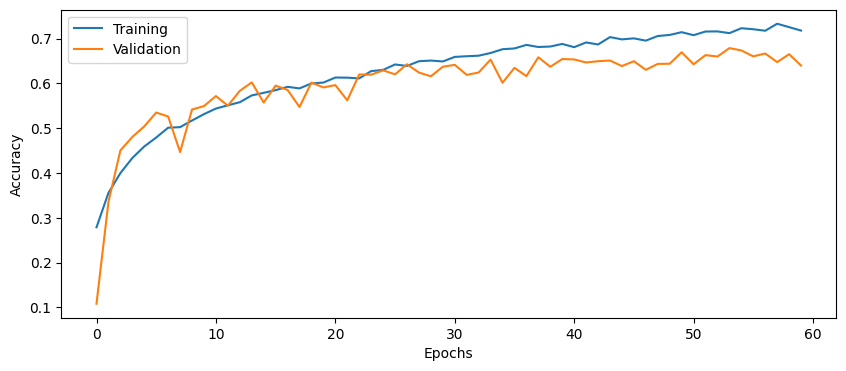

In [27]:
# Plot the history from the training run
plot_results(history6)

## Plot misclassified images

Lets plot some images where the CNN performed badly.

In [28]:
# Find misclassified images
y_pred=model6.predict(Xtest, verbose=0) 
y_pred=np.argmax(y_pred,axis=1)

y_correct = np.argmax(Ytest,axis=-1)

miss = np.flatnonzero(y_correct != y_pred)

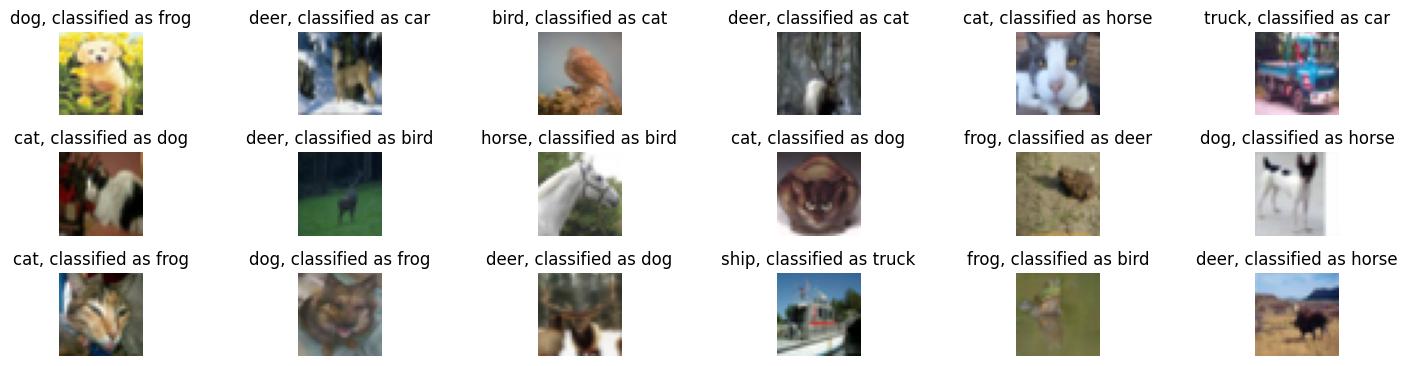

In [29]:
# Plot a few of them
plt.figure(figsize=(15,4))
perm = np.random.permutation(miss)
for i in range(18):
    im = (Xtest[perm[i]] + 1) * 127.5
    im = im.astype('int')
    label_correct = y_correct[perm[i]]
    label_pred = y_pred[perm[i]]
    
    plt.subplot(3,6,i+1)
    plt.tight_layout()
    plt.imshow(im)
    plt.axis('off')
    plt.title("{}, classified as {}".format(classes[label_correct], classes[label_pred]))
plt.show()

##  5.3 Testing on another size

#### **<span style="color:red">Questions</span>**

28. This CNN has been trained on 32 x 32 images, can it be applied to images of another size? If not, why is this the case?

29. Is it possible to design a CNN that can be trained on images of one size, and then applied to an image of any size? How?

#### **<span style="color:green">Answers</span>**
[Your answer here]

28) No it cannot be applied to images of another size because the dense layer after Flatten expects exactly 2048 inputs, so an image of another size will give a different number of inputs and it will not work.
29) Yes, by using global average pooling instead of Flatten because it gives one value per channel no matter what the image size is, so the dense layer always gets the same number of inputs.

# Part 6: Carbon footprint

In this next section we will evaluate the carbon footprint of training our CNN model. In particular we will look at the effect of training hyper parameters of carbon footprint. You can read more about this topic [here](https://arxiv.org/abs/2007.03051) or [here](https://research.google/blog/good-news-about-the-carbon-footprint-of-machine-learning-training/). 

In this lab we will use the `carbontracker` library that easily integrates with any model training routine. See the example in the [documentation](https://github.com/lfwa/carbontracker?tab=readme-ov-file) on how to use the carbon tracker.

#### **<span style="color:red">Questions</span>**

28. Keeping the model architecture fixed, which training parameter impacts the carbon footprint? 
    
29. The choice of batch size can dramatically impact carbon foot print: why is this the case?
    
30. Assume that you have a model with 100 million parameters running in the backend of a service with 5 million users. How can the carbon footprint of using this model be reduced?

#### **<span style="color:green">Answers</span>**
[Your answer here]

28) The number of epochs impacts the carbon footprint by keeping the model architecture fixed because more epochs means longer training time and more energy used. For our 20 epochs CarbonTracker measured 0.000900 kWh and 0.433 g CO2.
29) Because with small batches the GPU is not fully used and there are more steps per epoch, so the training takes longer and uses more energy.
30) The carbon footprint can be reduced by making the model smaller i.e., with quantization or pruning which makes each prediction use less energy and by running it on servers that use green energy.

In [30]:
from carbontracker.tracker import CarbonTracker

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Setup training parameters
batch_size = 32
epochs = 20
input_shape = Xtrain.shape[1:]

# Build model (your best config)
model7 = build_CNN(input_shape, loss,
                   n_conv_layers=3, n_filters=32, n_dense_layers=1, n_nodes=128,
                   use_dropout=True,
                   learning_rate=0.001, act_fun='relu', optimizer='adam')

# Create a CarbonTracker object
tracker = CarbonTracker(epochs=epochs)

for epoch in range(epochs):
    # start carbon tracking
    tracker.epoch_start()
    # fit model
    model7.fit(Xtrain, Ytrain,
               batch_size=batch_size,
               epochs=1,
               validation_data=(Xval, Yval),
               verbose=1)
    tracker.epoch_end()

tracker.stop()

# ============================================


Status code Unknown from http://ipinfo.io/json: ERROR - HTTPConnectionPool(host='ipinfo.io', port=80): Max retries exceeded with url: /json (Caused by NameResolutionError("<urllib3.connection.HTTPConnection object at 0x7c0d76a820c0>: Failed to resolve 'ipinfo.io' ([Errno -3] Temporary failure in name resolution)"))


CarbonTracker: The following components were found: GPU with device(s) NVIDIA GeForce RTX 3060 Laptop GPU.
CarbonTracker: WARNING - ElectricityMaps API key not set. Will default to average carbon intensity.
CarbonTracker: WARNING - Failed to retrieve carbon intensity: Defaulting to average carbon intensity 481 gCO2/kWh.
235/235 [==============================] - 10s 22ms/step - loss: 2.0749 - accuracy: 0.3432 - val_loss: 2.8876 - val_accuracy: 0.1868
CarbonTracker: WARNING - ElectricityMaps API key not set. Will default to average carbon intensity.
CarbonTracker: WARNING - Failed to retrieve carbon intensity: Defaulting to average carbon intensity 481 gCO2/kWh.
CarbonTracker: Live carbon intensity could not be fetched at detected location: Unknown. Defaulted to average carbon intensity for world in 2019 of 481.00 gCO2/kWh. at detected location: Malmö, Skåne, SE.
CarbonTracker: 
Predicted consumption for 20 epoch(s):
	Time:	0:03:44
	Energy:	0.002340945159 kWh
	CO2eq:	1.125994621529 g
	T

# Part 7: Pre-trained 2D CNNs

There are many deep 2D CNNs that have been pre-trained using the large ImageNet database (several million images, 1000 classes). Import a pre-trained ResNet50 network from Keras applications. Show the network using `model.summary()`

#### **<span style="color:red">Questions</span>**

31. How many convolutional layers does ResNet50 have? 

32. How many trainable parameters does the ResNet50 network have? 

33. What is the size of the images that ResNet50 expects as input?

34. Using the answer to question 30, explain why the second derivative is seldom used when training deep networks.

35. What do you expect the carbon footprint of using pre-trained networks to be compared to training a model from scratch?

#### **<span style="color:green">Answers</span>**
[Your answer here]

31) ResNet50 has 53 Conv2D layers.
32) ResNet50 has 25,583,592 trainable parameters.
33) ResNet50 expects images of size 224 x 224 x 3.
34) Because with 25 million parameters the second derivative will be a 25M x 25M matrix, which is way too big to store in memory and compute.
35) I expect carbon footprint will be much lower because the model is already trained and we only use it for prediction whereas training from scratch takes a lot of time and energy.


After loading the pre-trained CNN, apply it to 5 random color images that you download and copy to the cloud machine or your own computer. Are the predictions correct? How certain is the network of each image class?


These pre-trained networks can be fine tuned to your specific data, and normally only the last layers need to be re-trained, but it will still be too time consuming to do in this elaboration.

Some useful functions:
- `load_img` and `img_to_array` in [tf_keras.utils](https://www.tensorflow.org/api_docs/python/tf/keras/utils).
- `ResNet50` in [tf_keras.applications.ResNet50](tf.keras.applications.ResNet50).
- `preprocess_input` in [tf_keras.applications.resnet](https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet/preprocess_input).
- `decode_predictions` in [tf_keras.applications.resnet](https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet/decode_predictions).
- `expand_dims` in [numpy](https://numpy.org/doc/stable/reference/generated/numpy.expand_dims.html).

See [keras applications](https://keras.io/api/applications/) and the keras [resnet50-function](https://keras.io/api/applications/resnet/#resnet50-function) for more details.

In [33]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# import the necessary libraries and functions 
from tf_keras.applications import ResNet50
from tf_keras.utils import load_img, img_to_array
from tf_keras.applications.resnet import preprocess_input, decode_predictions

# load the pre-trained ResNet50 model
resnet50 = ResNet50(weights='imagenet')

# print the model summary
resnet50.summary()

# Counting the convolutional layers
n_conv = len([l for l in resnet50.layers if 'Conv2D' in type(l).__name__])
print(f'\nResNet50 has {n_conv} Conv2D layers and {resnet50.count_params():,} parameters')
print(f'Expected input shape: {resnet50.input_shape}\n')

# load the image and preprocess it
images = ['image1.jpeg', 'image2.jpeg', 'image3.jpeg', 'image4.jpeg', 'image5.jpeg']

for i in images:
    # ResNet50 expects 224 x 224 RGB images
    image = load_img(i, target_size=(224, 224))
    image = img_to_array(image)                
    image = np.expand_dims(image, axis=0) 
    image = preprocess_input(image)  
    # predict the image
    prediction = resnet50.predict(image, verbose=0)
    label = decode_predictions(prediction, top=3)[0]
    # print the predicted label
    print(f'{i}:')
    for (_, name, probability) in label:
        print(f'   {name:<25s} {100*probability:.2f} %')

# ============================================

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_10 (InputLayer)       [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_10[0][0]']            
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                       

After loading the pre-trained CNN, apply it to 5 random color images that you download and copy to the cloud machine or your own computer. Are the predictions correct? How certain is the network of each image class?

Answer) image1 is a tiger and it was classified as tiger (69.95 %) which is correct, and the second guess was tiger_cat (23.82 %) which is very similar. image2 is a red panda and it was classified as lesser_panda (98.80 %) which is correct since lesser panda is another name for red panda. image3 is a sea turtle and it was classified as loggerhead (59.22 %) and leatherback_turtle (40.30 %), so it knows it is a sea turtle but it is not sure which type. image4 is a toucan and it was classified as toucan (99.30 %) which is correct. image5 is a humpback whale jumping out of the water and it was classified as grey_whale (99.67 %) which is almost correct, because humpback whale is not a class in ImageNet. The network is very certain for image2, image4 and image5 (above 98 %) whereas for image1 (69.95 %) and image3 (59.22 %) it is less certain because the top two classes are very similar.

# Part 8 (OPTIONAL)

Set up `Ray Tune` and run automatic hyper parameter optimization for the CNN model as we have done in the DNN lab. Remember that you have to define the `train_CNN` function, specify the hyper parameter search space and the number of samples to evaluate, among other.